## Numerical PDE Methods 2

In [57]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import diags, eye, kron
from scipy.sparse.linalg import spsolve

### Problem 1:
Right-sided, left-sided, and up-wind methods for solving given transport equation:

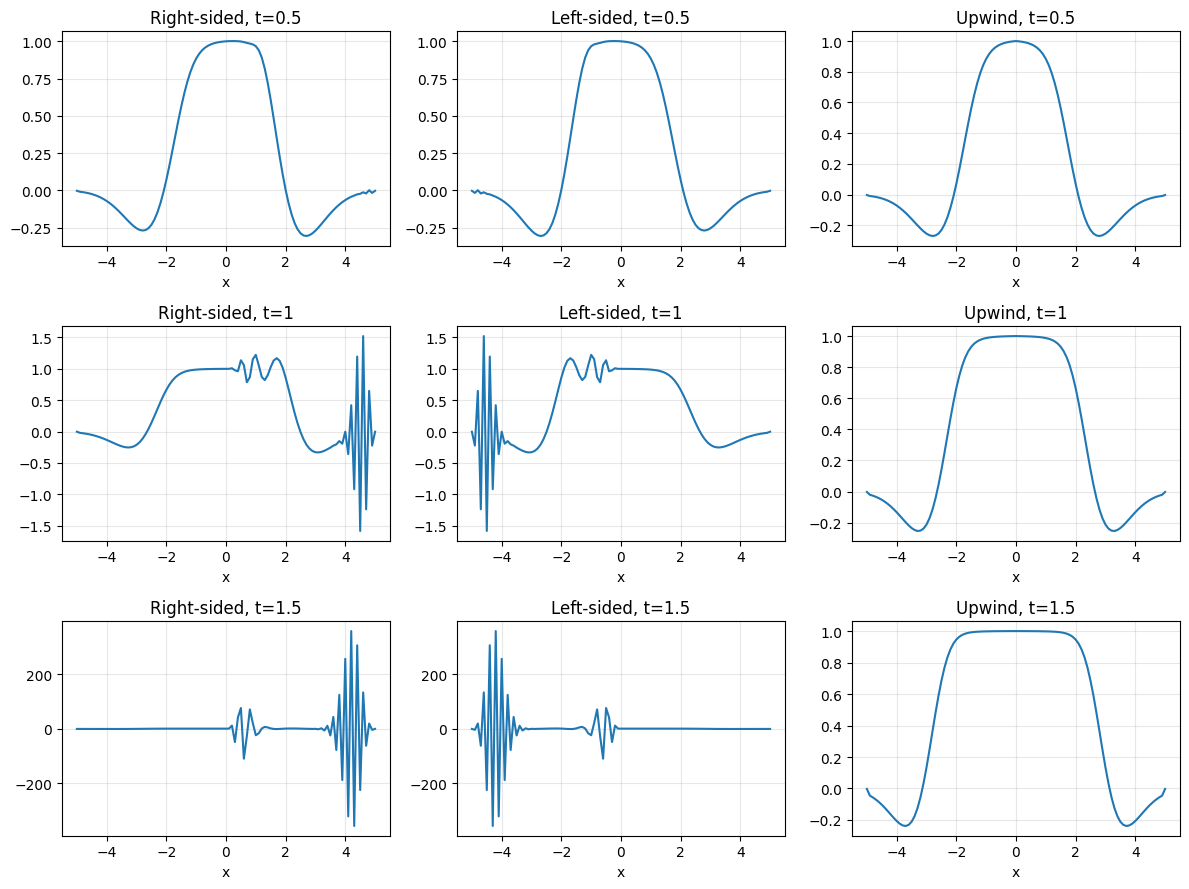

In [58]:
dx, dt = 0.1, 0.025
Nx = int(10/dx)
Nt = int(1.5/dt)

x = np.linspace(-5,5, int(10/dx) + 1)
t = np.linspace(0, 1.5, )

f = (1 - x**2/2) * np.exp(-x**2/3)
c = 3*x / (1 + x**2)
sigma = c * dt / dx

# Three separate solutions
R = f.copy()  # right-sided
L = f.copy()  # left-sided
U = f.copy()  # upwind

results = {}

for n in range(1, Nt + 1):

    Rnew = R.copy()
    Lnew = L.copy()
    Unew = U.copy()

    # (a) Right-sided difference
    Rnew[1:-1] = (1 + sigma[1:-1])*R[1:-1] \
                 - sigma[1:-1]*R[2:]

    # (b) Left-sided difference
    Lnew[1:-1] = (1 - sigma[1:-1])*L[1:-1] \
                 + sigma[1:-1]*L[:-2]

    # (c) Upwind difference
    for m in range(1, len(x)-1):
        if c[m] >= 0:
            Unew[m] = (1-sigma[m])*U[m] \
                      + sigma[m]*U[m-1]
        else:
            Unew[m] = (1+sigma[m])*U[m] \
                      - sigma[m]*U[m+1]

    # Keep endpoints fixed at their initial values
    R, L, U = Rnew, Lnew, Unew

    if n in [20, 40, 60]:
        results[n * dt] = (R.copy(), L.copy(), U.copy())

fig, axes = plt.subplots(3, 3, figsize=(12, 9))

for row, (t, sol) in enumerate(results.items()):
    for col, (name, y) in enumerate(zip(
        ["Right-sided", "Left-sided", "Upwind"], sol
    )):
        axes[row, col].plot(x, y)
        axes[row, col].set_title(f"{name}, t={t:g}")
        axes[row, col].set_xlabel("x")
        axes[row, col].grid(alpha=0.3)

plt.tight_layout()
plt.show()

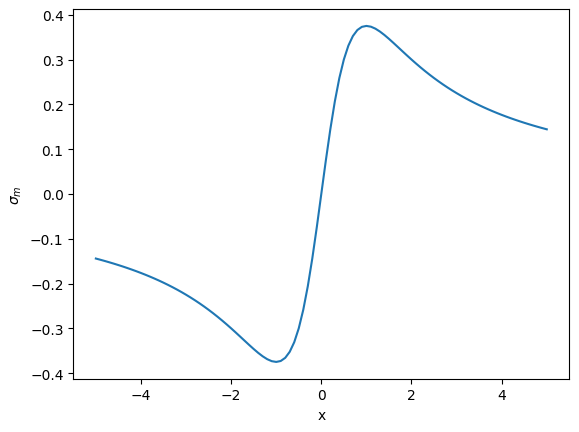

In [59]:
plt.plot(x, sigma)
plt.xlabel("x")
plt.ylabel(r"$\sigma_m$")
plt.show()


### Problem 2

Wave equation:

In [60]:
def solve_wave(omega, dt, T=20, dx=0.01):
    x = np.linspace(0, 5, int(5/dx) + 1)
    Nt = int(round(T/dt))
    sigma = dt/dx

    # t = 0
    u_prev = np.zeros(len(x))

    # t = dt
    u = np.zeros(len(x))
    u[0] = np.sin(omega*dt)
    u[-1] = 0

    # Store solutions for plotting
    snapshots = {0.0: u_prev.copy()}
    amplitudes = [0, np.max(np.abs(u))]
    times = [0, dt]

    for n in range(1, Nt):
        u_next = np.zeros_like(u)

        u_next[1:-1] = (
            2*u[1:-1] - u_prev[1:-1]
            + sigma**2 * (
                u[2:] - 2*u[1:-1] + u[:-2]
            )
        )

        # Boundary conditions
        u_next[0] = np.sin(omega*(n+1)*dt)
        u_next[-1] = 0

        u_prev, u = u, u_next
        t = (n+1)*dt

        times.append(t)
        amplitudes.append(np.max(np.abs(u)))

        if np.max(np.abs(u)) > 1e100:
            print("Diverging amplitudes, simulation halted")
            break

        # save snapshot whenever t is within half a time step of one of the target times
        if any(abs(t-s) < dt/2 for s in [2, 5, 10, 15, 20]):
            snapshots[round(t, 2)] = u.copy()

    return x, snapshots, np.array(times), np.array(amplitudes)

Diverging amplitudes, simulation halted


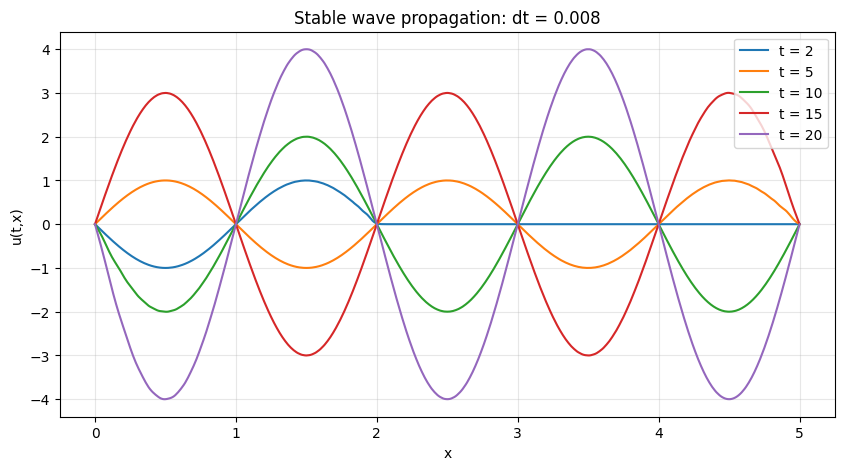

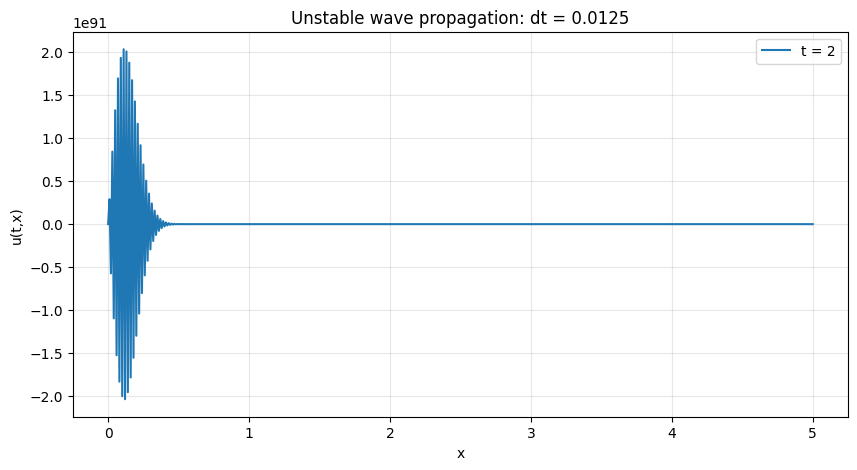

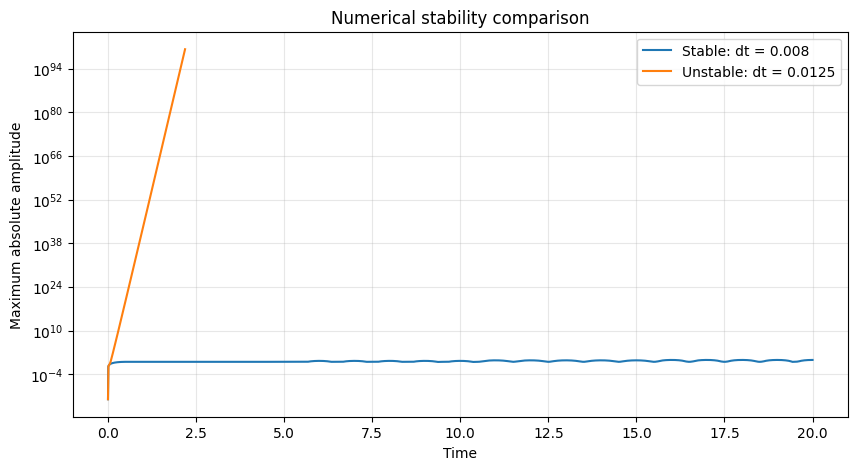

In [61]:
omega = np.pi

x, stable, ts, As = solve_wave(omega, dt=0.008)
_, unstable, tu, Au = solve_wave(omega, dt=0.0125)

# Plot 1: Stable wave profiles at different times
plt.figure(figsize=(10, 5))

for t, u in stable.items():
    if t > 0:
        plt.plot(x, u, label=f"t = {t:g}")

plt.xlabel("x")
plt.ylabel("u(t,x)")
plt.title("Stable wave propagation: dt = 0.008")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Plot 2: Unstable wave profiles at different times
plt.figure(figsize=(10, 5))

for t, u in unstable.items():
    if t > 0:
        plt.plot(x, u, label=f"t = {t:g}")

plt.xlabel("x")
plt.ylabel("u(t,x)")
plt.title("Unstable wave propagation: dt = 0.0125")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Plot 3: Compare maximum amplitudes
plt.figure(figsize=(10, 5))

plt.semilogy(ts, np.maximum(As, 1e-12),
             label="Stable: dt = 0.008")
plt.semilogy(tu, np.maximum(Au, 1e-12),
             label="Unstable: dt = 0.0125")

plt.xlabel("Time")
plt.ylabel("Maximum absolute amplitude")
plt.title("Numerical stability comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

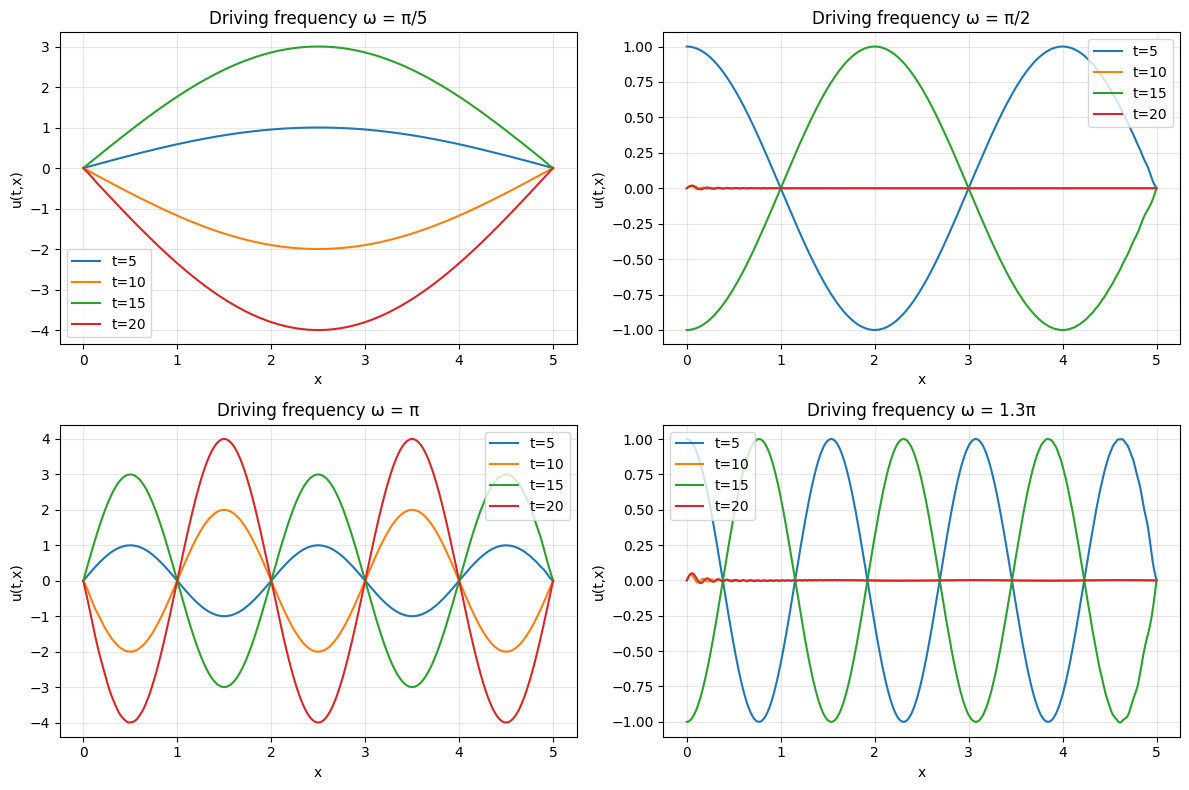

In [62]:
omegas = [np.pi/5, np.pi/2, np.pi, 1.3*np.pi]
labels = ["π/5", "π/2", "π", "1.3π"]

dt = 0.008

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, omega, label in zip(axes.flat, omegas, labels):
    x, snapshots, times, amplitudes = solve_wave(omega, dt)

    for t in [5, 10, 15, 20]:
        ax.plot(x, snapshots[t], label=f"t={t}")

    ax.set_title(f"Driving frequency ω = {label}")
    ax.set_xlabel("x")
    ax.set_ylabel("u(t,x)")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Problem 3

Non-linear transport and numerically solving the conservation law:

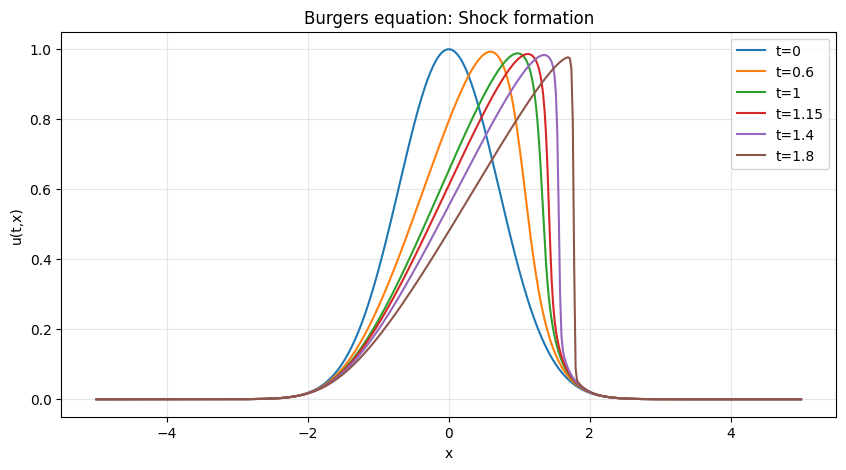

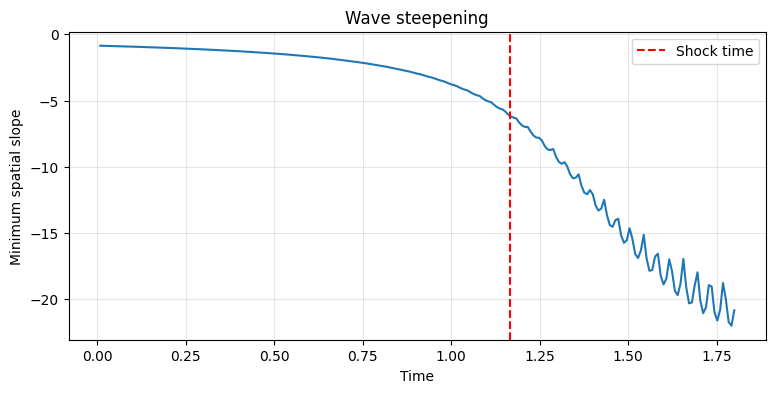

In [63]:
dx, dt = 0.02, 0.008
x = np.arange(-5, 5 + dx/2, dx)
T = 1.8

u = np.exp(-x**2)
t_shock = np.sqrt(np.e / 2)

plot_times = [0, 0.6, 1.0, 1.15, 1.4, 1.8]
snapshots = {0: u.copy()}
slopes = []
times = []

Nt = int(round(T/dt))

for n in range(1, Nt + 1):
    unew = u.copy()

    # Conservative upwind scheme
    unew[1:] = u[1:] - dt/(2*dx) * (
        u[1:]**2 - u[:-1]**2
    )

    # Left boundary: negligible gaussian tail
    unew[0] = 0

    u = unew
    t = n*dt

    # Smallest numeric deerivative (for steepness)
    slopes.append(np.min(np.diff(u)/dx))
    times.append(t)

    for tp in plot_times[1:]:
        if abs(t-tp) <= dt/2:
            snapshots[tp] = u.copy()

# Plot solution profiles
plt.figure(figsize=(10, 5))

for t, sol in snapshots.items():
    plt.plot(x, sol, label=f"t={t:g}")

plt.xlabel("x")
plt.ylabel("u(t,x)")
plt.title("Burgers equation: Shock formation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Plot steepening of the wave
plt.figure(figsize=(9, 4))

plt.plot(times, slopes)
plt.axvline(t_shock, linestyle="--",
            color="red", label="Shock time")

plt.xlabel("Time")
plt.ylabel("Minimum spatial slope")
plt.title("Wave steepening")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Problem 4

2D Laplace equation with inhomogenous boundary:

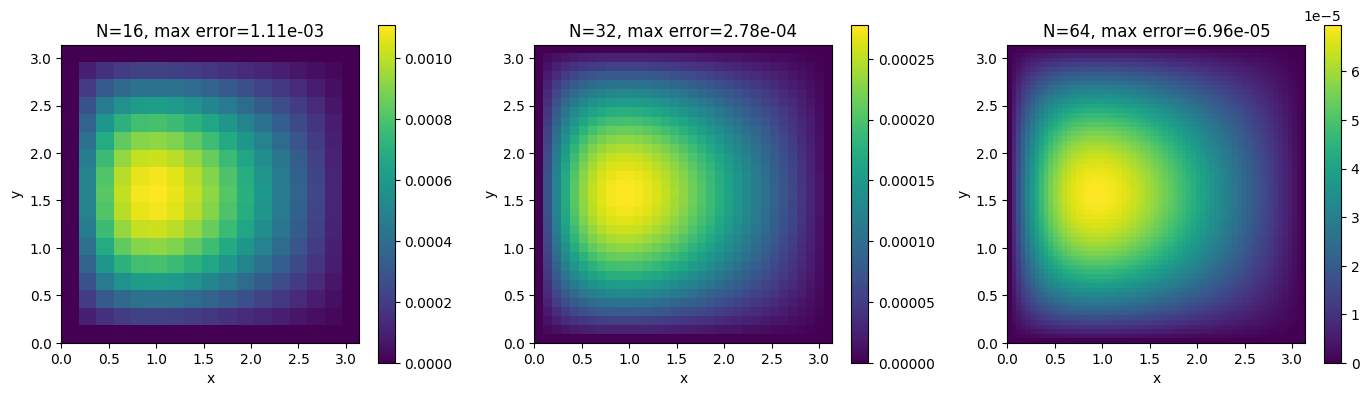

N= 16: error=1.109e-03, ratio=3.898
N= 32: error=2.780e-04, ratio=3.989
N= 64: error=6.963e-05, ratio=3.992
N=128: error=1.741e-05, ratio=3.999


In [67]:
# Compare numerical errors for different grid sizes
Ns = [8, 16, 32, 64, 128]
errors = []
hs = []
error_fields = {}

for N in Ns:
    n = N - 1
    x = np.linspace(0, np.pi, N+1)
    y = x.copy()
    h = np.pi/N

    # Construct finite-difference matrix
    T = diags(
        [-np.ones(n-1), 2*np.ones(n), -np.ones(n-1)],
        [-1, 0, 1], format="csr"
    )
    I = eye(n, format="csr")
    A = kron(I, T) + kron(T, I)

    # Boundary contributions
    b = np.zeros((n, n))
    b[0, :] = np.sin(y[1:-1])

    # Numerical solution
    U = np.zeros((N+1, N+1))
    U[0, :] = np.sin(y)
    U[1:-1, 1:-1] = spsolve(A, b.ravel()).reshape(n, n)

    # Exact solution
    X, Y = np.meshgrid(x, y, indexing="ij")
    U_exact = np.sin(Y)*np.sinh(np.pi-X)/np.sinh(np.pi)

    # Absolute error
    E = np.abs(U - U_exact)
    errors.append(E.max())
    hs.append(h)
    error_fields[N] = E

# 1. Plot error distributions
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, N in zip(axes, [16, 32, 64]):
    im = ax.imshow(
        error_fields[N].T,
        origin="lower",
        extent=[0, np.pi, 0, np.pi],
        cmap="viridis"
    )
    ax.set_title(f"N={N}, max error={error_fields[N].max():.2e}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    fig.colorbar(im, ax=ax)

plt.tight_layout()
plt.show()

# Error ratios
for i in range(1, len(Ns)):
    ratio = errors[i-1] / errors[i]
    print(f"N={Ns[i]:3d}: error={errors[i]:.3e}, "f"ratio={ratio:.3f}")